# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

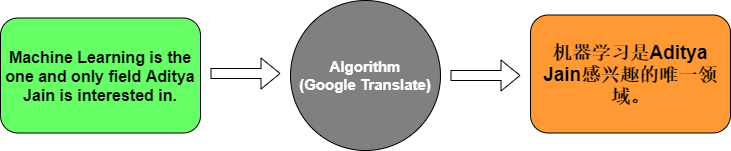

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.0000e+00 - loss: 2.4834 - val_accuracy: 0.0000e+00 - val_loss: 2.4865
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.5714 - loss: 2.4740 - val_accuracy: 0.0000e+00 - val_loss: 2.4886
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.5714 - loss: 2.4641 - val_accuracy: 0.0000e+00 - val_loss: 2.4908
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4533 - val_accuracy: 0.0000e+00 - val_loss: 2.4933
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.5714 - loss: 2.4410 - val_accuracy: 0.0000e+00 - val_loss: 2.4961
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.5714 - loss: 2.4269 - val_accuracy: 0.0000e+00 - val_loss: 2.4993
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.5714 - loss: 2.4104 - val_accuracy: 0.0000e+00 - val_loss: 2.5030
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.5714 - loss: 2.3910 - val

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 771ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1.**
It converts a word index into a dense, learnable numeric vector, instead of a meaningless integers, the model gets a vector in which words with similar meaning/usage end up close together. 

**2.**
It reads the input sequence one word at a time and builds an internal representation of its meaning and order. Its final hidden and cell states act as a context vector in the model summarizing the whole input, which is passed to the decoder.

**3.**
It takes the context vector and generates the output sentence one token at a time, producing a hidden state for each output position, since it has memory, each step can take into account the previous steps, so word order and grammar of the target language are modelled. 

**4.**
Softmax converts the model’s raw scores (logits) for every word in into probabilities that are between 0 and 1 and sum to 1, so the model can select or sample the most likely next word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
import os, re, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [9]:
# load data
CSV_PATH = "eng_french.csv" 
MAX_WORDS = 8            
N_SAMPLES = 20000

df = pd.read_csv(CSV_PATH)
df.columns = ["english", "french"]

print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
#clean
def clean(s):
    s = str(s).lower().strip()
    s = re.sub(r"([?.!,¿¡])", r" \1 ", s)        
    s = re.sub(r"[^a-zàâäçéèêëîïôöùûüÿœæ?.!,'\- ]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

df = df.dropna().drop_duplicates()
df["english"] = df["english"].apply(clean)
df["french"]  = df["french"].apply(clean)

df = df[(df.english.str.split().str.len() <= MAX_WORDS) & (df.french.str.split().str.len() <= MAX_WORDS)]
df = df.sample(n=min(N_SAMPLES, len(df)), random_state=42).reset_index(drop=True)

df["french_in"]  = "sos " + df["french"]        # decoder input
df["french_out"] = df["french"] + " eos"        # decoder target
print(len(df), "sentence pairs")
df.head()

20000 sentence pairs


,english,french,french_in,french_out
0,you could sleep in the hammock .,vous pourriez dormir dans le hamac .,sos vous pourriez dormir dans le hamac .,vous pourriez dormir dans le hamac . eos
1,tom likes singing in the shower .,tom aime chanter sous la douche .,sos tom aime chanter sous la douche .,tom aime chanter sous la douche . eos
2,well done !,bien cuit !,sos bien cuit !,bien cuit ! eos
3,she divorced her husband .,elle divorça de son mari .,sos elle divorça de son mari .,elle divorça de son mari . eos
4,learning foreign languages is boring .,"apprendre des langues étrangères , c'est ennuy...","sos apprendre des langues étrangères , c'est e...","apprendre des langues étrangères , c'est ennuy..."


In [11]:
#tokenize
tok_eng = Tokenizer(filters="")
tok_eng.fit_on_texts(df.english)
tok_frn = Tokenizer(filters="")
tok_frn.fit_on_texts(["sos eos"] + list(df.french))

eng_vocab = len(tok_eng.word_index) + 1
frn_vocab = len(tok_frn.word_index) + 1
print("English vocab:", eng_vocab, "| French vocab:", frn_vocab)

eng_seq = tok_eng.texts_to_sequences(df.english)
frn_in_seq = tok_frn.texts_to_sequences(df.french_in)
frn_out_seq = tok_frn.texts_to_sequences(df.french_out)

max_eng = max(len(s) for s in eng_seq)
max_frn = max(len(s) for s in frn_in_seq)

English vocab: 5699 | French vocab: 9779


In [12]:
#pad
X = pad_sequences(eng_seq, maxlen=max_eng, padding="post")
dec_in = pad_sequences(frn_in_seq, maxlen=max_frn, padding="post")
dec_out = pad_sequences(frn_out_seq, maxlen=max_frn, padding="post")
print(X.shape, dec_in.shape, dec_out.shape)

X_tr, X_te, din_tr, din_te, dout_tr, dout_te = train_test_split(
    X, dec_in, dec_out, test_size=0.1, random_state=42)

(20000, 8) (20000, 9) (20000, 9)


In [13]:
#build seq2seq model
EMB, UNITS = 128, 256

#encoder
enc_inputs = Input(shape=(max_eng,), name="encoder_input")
enc_emb = Embedding(eng_vocab, EMB, mask_zero=True, name="enc_embedding")(enc_inputs)
_, state_h, state_c = LSTM(UNITS, return_state=True, name="encoder_lstm")(enc_emb)   # context vector

#decoder
dec_inputs = Input(shape=(None,), name="decoder_input")
dec_emb_lyr = Embedding(frn_vocab, EMB, mask_zero=True, name="dec_embedding")
dec_lstm = LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
dec_dense = Dense(frn_vocab, activation="softmax", name="output")

dec_seq, _, _ = dec_lstm(dec_emb_lyr(dec_inputs), initial_state=[state_h, state_c])
outputs = dec_dense(dec_seq)

model = Model([enc_inputs, dec_inputs], outputs)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)    │ (None, 8)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder_input (InputLayer)    │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ enc_embedding (Embedding)     │ (None, 8, 128)            │         729,472 │ encoder_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 8)                 │               0 │ encoder_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dec_embedding (Embedding)     │ (None, None, 128)         │       1,251,712 │ decoder_input[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ encoder_lstm (LSTM)           │ [(None, 256), (None,      │         394,240 │ enc_embedding[0][0],       │
│                               │ 256), (None, 256)]        │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ decoder_lstm (LSTM)           │ [(None, None, 256),       │         394,240 │ dec_embedding[0][0],       │
│                               │ (None, 256), (None, 256)] │                 │ encoder_lstm[0][1],        │
│                               │                           │                 │ encoder_lstm[0][2]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output (Dense)                │ (None, None, 9779)        │       2,513,203 │ decoder_lstm[0][0]         │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 5,282,867 (20.15 MB)

 Trainable params: 5,282,867 (20.15 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#train
history = model.fit([X_tr, din_tr], dout_tr,
                    batch_size=128, epochs=20, validation_split=0.1)

Epoch 1/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 56s 384ms/step - accuracy: 0.2185 - loss: 5.8458 - val_accuracy: 0.2952 - val_loss: 4.9583
Epoch 2/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 50s 393ms/step - accuracy: 0.3041 - loss: 4.7186 - val_accuracy: 0.3111 - val_loss: 4.6799
Epoch 3/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 49s 385ms/step - accuracy: 0.3182 - loss: 4.4322 - val_accuracy: 0.3255 - val_loss: 4.5264
Epoch 4/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 48s 380ms/step - accuracy: 0.3303 - loss: 4.2247 - val_accuracy: 0.3327 - val_loss: 4.3854
Epoch 5/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 48s 376ms/step - accuracy: 0.3581 - loss: 3.9803 - val_accuracy: 0.3703 - val_loss: 4.1633
Epoch 6/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 50s 390ms/step - accuracy: 0.3838 - loss: 3.7373 - val_accuracy: 0.3956 - val_loss: 4.0118
Epoch 7/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 50s 390ms/step - accuracy: 0.4133 - loss: 3.5215 - val_accuracy: 0.4114 - val_loss: 3.8770
Epoch 8/20
127/127 ━━━━━━━━━━━━━━━━━━━━ 50s 397ms/step - accuracy: 0.4367 - loss: 3

In [15]:
#evaluate
loss, acc = model.evaluate([X_te, din_te], dout_te, verbose=0)
print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")

Test loss: 3.2457 | Test accuracy: 0.5056


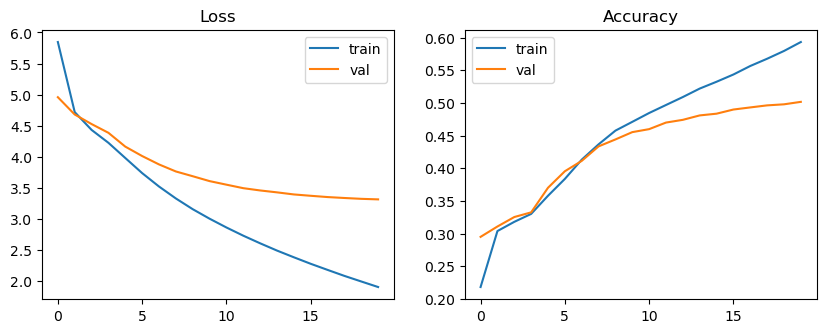

In [16]:
#visualiz
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

In [17]:
#inference
encoder_model = Model(enc_inputs, [state_h, state_c])

h_in = Input(shape=(UNITS,)); c_in = Input(shape=(UNITS,))
tok_in = Input(shape=(1,))
d_out, h_out, c_out = dec_lstm(dec_emb_lyr(tok_in), initial_state=[h_in, c_in])
decoder_model = Model([tok_in, h_in, c_in], [dec_dense(d_out), h_out, c_out])

idx2frn = {i: w for w, i in tok_frn.word_index.items()}

def translate(sentence):
    seq = tok_eng.texts_to_sequences([clean(sentence)])
    seq = pad_sequences(seq, maxlen=max_eng, padding="post")
    h, c = encoder_model.predict(seq, verbose=0)

    word = np.array([[tok_frn.word_index["sos"]]])
    result = []
    for _ in range(max_frn + 2):
        probs, h, c = decoder_model.predict([word, h, c], verbose=0)
        next_id = int(np.argmax(probs[0, -1]))
        w = idx2frn.get(next_id, "")
        if w == "eos" or w == "":
            break
        result.append(w)
        word = np.array([[next_id]])
    return " ".join(result)

for s in ["Hello", "How are you?", "I love you", "Thank you", "I am hungry", "Where are you?"]:
    print(f"{s:20s} -> {translate(s)}")

Hello                -> 
How are you?         -> qu'est-ce qui sont ?
I love you           -> je suis ici ?
Thank you            -> où vous plaît ?
I am hungry          -> je suis détendue .
Where are you?       -> où es-tu ?
